In [1]:
from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import jax, jax.numpy as jnp
import matplotlib, matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

import scienceplots

import USA
from models import Parameters, SIR, SEIR, SEIRD

plt.style.use([
    'science',
    'no-latex'
    ])
plt.rcParams['text.latex.preamble'] = r'\usepackage{newtxmath, newtxtext}'
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.Set1.colors)

FIGSIZE = (2.5, 2.5*3/4)

In [ ]:
# R0 = 12-18
# contagious period ~ 9 days
# latent period ~ 11 days
p = Parameters(alpha=1/9, beta=12/9, gamma=0, delta = 1/11, W=0.1*USA.get_od_matrix())
solver = Tsit5()

t0 = 0.0
t1 = 200.0
dt_fine = 1.0
dt_coarse = 2.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt_fine, dt_fine))

y0 = USA.make_initial_condition(initial_county=36047, initial_vaccination_rate=0.0)

In [15]:
fine_sol = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt_fine, y0=y0, args=p, saveat=saveat)
coarse_sol = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt_coarse, y0=y0, args=p, saveat=saveat)
print(fine_sol.stats)
print(coarse_sol.stats)

{'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
{'max_steps': 4096, 'num_accepted_steps': Array(100, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(100, dtype=int64, weak_type=True)}


In [16]:
ts = fine_sol.ts
ys_fine = fine_sol.ys.reshape((-1, 4, p.n_cities)) # type: ignore
ys_coarse = coarse_sol.ys.reshape((-1, 4, p.n_cities)) # type: ignore

Maximum relative error: 4.057825752919978e-07


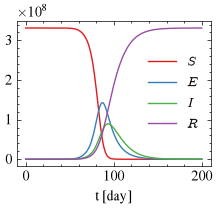

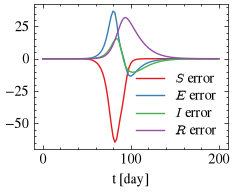

In [17]:
# plot S, E, I, R reduced over counties
plt.figure(figsize=FIGSIZE)
S_fine = jnp.sum(ys_fine[:, 0, :], axis=1)
E_fine = jnp.sum(ys_fine[:, 1, :], axis=1)
I_fine = jnp.sum(ys_fine[:, 2, :], axis=1)
R_fine = jnp.sum(ys_fine[:, 3, :], axis=1)
plt.plot(ts, S_fine, label=r"$S$")
plt.plot(ts, E_fine, label=r"$E$")
plt.plot(ts, I_fine, label=r"$I$")
plt.plot(ts, R_fine, label=r"$R$")
plt.xlabel("t [day]")
plt.legend()
plt.savefig("../figures/SEIR.pdf")

S_coarse = jnp.sum(ys_coarse[:, 0, :], axis=1)
E_coarse = jnp.sum(ys_coarse[:, 1, :], axis=1)
I_coarse = jnp.sum(ys_coarse[:, 2, :], axis=1)
R_coarse = jnp.sum(ys_coarse[:, 3, :], axis=1)

S_error = (S_fine - S_coarse) / (2**solver.order(SEIR) - 1)
E_error = (E_fine - E_coarse) / (2**solver.order(SEIR) - 1)
I_error = (I_fine - I_coarse) / (2**solver.order(SEIR) - 1)
R_error = (R_fine - R_coarse) / (2**solver.order(SEIR) - 1)

plt.figure(figsize=FIGSIZE)
plt.plot(ts[::2], S_error[::2], label=r"$S$ error")
plt.plot(ts[::2], E_error[::2], label=r"$E$ error")
plt.plot(ts[::2], I_error[::2], label=r"$I$ error")
plt.plot(ts[::2], R_error[::2], label=r"$R$ error")
plt.xlabel("t [day]")
plt.legend(labelspacing=0.25, borderpad=0.25, loc="lower right")
plt.savefig("../figures/SEIR_error.pdf")

error_norm = jnp.linalg.norm(jnp.vstack([S_error[::2], E_error[::2], I_error[::2], R_error[::2]]), axis=0, ord=2)
ys_norm = jnp.linalg.norm(jnp.vstack([S_fine[::2], E_fine[::2], I_fine[::2], R_fine[::2]]), axis=0, ord=2)
print(f"Maximum relative error: {jnp.max(error_norm/ys_norm)}")

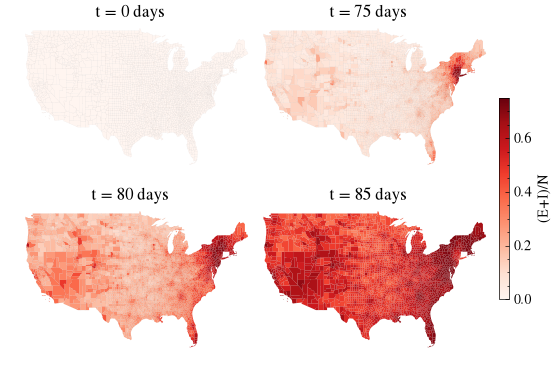

In [19]:
# plot 2x2 geographical plots of E+I/N

fig, ax = plt.subplots(2, 2, figsize=(6.5, 6.5*3/4), sharex=True, sharey=True)
# decrease space between subplots
plt.subplots_adjust(wspace=-0.05, hspace=-0.05)

for i, day in enumerate([0, 75, 80, 85]):
    gdf = USA.get_gdf()
    S, E, I, R = ys_fine[day, :, :]
    gdf["(E+I)/N"] = (E + I) / (S + E + I + R)
    gdf.plot(column="(E+I)/N", ax=ax.flatten()[i], cmap="Reds", edgecolor="black", linewidth=0.01, vmin=0, vmax=0.75)
    ax.flatten()[i].set_title(f"t = {day} days")
    ax.flatten()[i].set_xlim([-130, -65])
    ax.flatten()[i].set_ylim([20, 50])
    # remove axis
    ax.flatten()[i].axis("off")

# ax[0, 0].set_xlabel("")
# ax[0, 1].set_xlabel("")
# ax[0, 1].set_ylabel("")
# ax[1, 1].set_ylabel("")

sm = plt.cm.ScalarMappable(cmap="Reds", norm=matplotlib.colors.Normalize(vmin=0, vmax=0.75))
sm._A = []
cbar = fig.colorbar(sm, ax=ax.flatten(), orientation="vertical", fraction=0.02, pad=0.01)
cbar.set_label("(E+I)/N")
plt.savefig("../figures/SEIR_USA_map.pdf")

In [ ]:
# Plot infectious population for different vaccination rates or quarantine factors
def plot_infection_peak(results, ts, parameter_name, figure_name, time_stop=np.inf, legend=False):
    mask = ts <= time_stop
    plt.figure(figsize=FIGSIZE)

    for parameter_value, ys in results.items():
        I_total = jnp.sum(ys[:, 2, :], axis=1)
        total_infected = np.trapezoid(np.asarray(I_total), x=np.asarray(ts))
        print(f"{parameter_name} = {parameter_value:.4f}: approximately {total_infected / 9:.0f} people")

        if parameter_name == "gamma":
            plt.plot(ts[mask], I_total[mask], label=fr"$\gamma = {parameter_value:.4f}$")
        elif parameter_name == "quarantine_factor":
            plt.plot(ts[mask], I_total[mask], label=fr"Q_f $= {parameter_value:.2f}$")
        else:
            plt.plot(ts[mask], I_total[mask], label=fr"{parameter_name}$= {parameter_value:.3f}$")

    #plt.xlim(0, time_stop)
    plt.xlabel(r"$t$ [day]")
    plt.ylabel("$I$")
    if legend:
        # plt.legend()
        plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.savefig(figure_name)

In [63]:
gamma_values = [0, 0.0025, 0.0050, 0.0075]
results_v = {} # store solutions in this dictionary

for gamma in gamma_values:
    # R0 = 12-18
    # contagious period ~ 8 days
    p = Parameters(alpha=1/9, beta=12/9, gamma=float(gamma), delta=1/11, W=0.1*USA.get_od_matrix())

    solution = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt_fine, y0=y0, args=p, saveat=saveat)
    
    ys = solution.ys.reshape((-1, 4, p.n_cities))
    results_v[float(gamma)] = ys # save simulation results

    print(f"gamma = {float(gamma):.5f}, solver stats = {solution.stats}")

ts = solution.ts

gamma = 0.00000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00250, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00500, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00750, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}


gamma = 0.0000: approximately 331247920 people
gamma = 0.0025: approximately 267744400 people
gamma = 0.0050: approximately 209413411 people
gamma = 0.0075: approximately 155820772 people


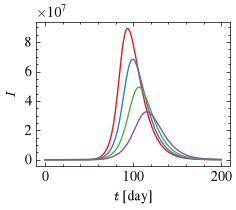

In [65]:
plot_infection_peak(results_v, ts, "gamma", "../figures/vaccination_rates.pdf")

In [66]:
gamma_values = [0, 0.0025, 0.0050, 0.0075]
results_quarantine_v = {} # store solutions in this dictionary

for gamma in gamma_values:
    # R0 = 12-18
    # contagious period ~ 8 days
    p = Parameters(alpha=1/9, beta=6/9, gamma=float(gamma), delta=1/11, W=0.1*USA.get_od_matrix())

    t1_long = 400
    saveat_long = SaveAt(ts=jnp.arange(t0, t1_long+dt_fine, dt_fine))
    solution = diffeqsolve(SEIR, solver, t0=0, t1=t1_long, dt0=dt_coarse, y0=y0, args=p, saveat=saveat_long)
    
    ys = solution.ys.reshape((-1, 4, p.n_cities))
    results_quarantine_v[float(gamma)] = ys # save simulation results

    print(f"gamma = {float(gamma):.5f}, solver stats = {solution.stats}")

ts = solution.ts

gamma = 0.00000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00250, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00500, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00750, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}


gamma = 0.0000: approximately 330383812 people
gamma = 0.0025: approximately 220463726 people
gamma = 0.0050: approximately 110282489 people
gamma = 0.0075: approximately 13779327 people


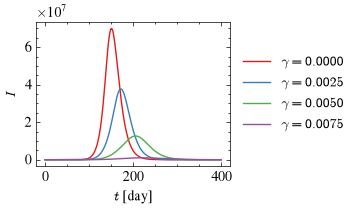

In [67]:
plot_infection_peak(results_quarantine_v, ts, "gamma", "../figures/vaccination_rates_quarantine.pdf", legend=True)

In [19]:
t0 = 0.0
t1 = 350.0
dt0 = 1.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0))

params = [
    {"beta": 12/9, "gamma": 0.0},
    {"beta": 12/9, "gamma": 0.0025},
    {"beta": 12/9, "gamma": 0.005},
    {"beta": 12/9, "gamma": 0.0075},
    {"beta": 6/9, "gamma": 0.0},
    {"beta": 6/9, "gamma": 0.0025},
    {"beta": 6/9, "gamma": 0.005},
    {"beta": 6/9, "gamma": 0.0075},
]

results_v = {}
solver = Tsit5()
y0 = USA.make_initial_condition(initial_county=36047, initial_vaccination_rate=0.0)
for param in params:
    beta = param["beta"]
    gamma = param["gamma"]
    p = Parameters(alpha=1/9, beta=beta, gamma=gamma, delta=1/11, W=0.1*USA.get_od_matrix())
    sol = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)
    print(f"beta = {beta:.5f}, gamma = {gamma:.5f}, solver stats = {sol.stats}")
    ts = sol.ts
    ys = sol.ys.reshape((-1, 4, p.n_cities))
    results_v[(beta, gamma)] = (ts, ys)

beta = 1.33333, gamma = 0.00000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(350, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(350, dtype=int64, weak_type=True)}
beta = 1.33333, gamma = 0.00250, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(350, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(350, dtype=int64, weak_type=True)}
beta = 1.33333, gamma = 0.00500, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(350, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(350, dtype=int64, weak_type=True)}
beta = 1.33333, gamma = 0.00750, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(350, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(350, dtype=int64, weak_type=True)}
beta = 0.66667, 

beta = 1.3333, gamma = 0.0000: approximately 100.00% of the population infected
beta = 1.3333, gamma = 0.0025: approximately 80.83% of the population infected
beta = 1.3333, gamma = 0.0050: approximately 63.24% of the population infected
beta = 1.3333, gamma = 0.0075: approximately 47.09% of the population infected
beta = 0.6667, gamma = 0.0000: approximately 99.73% of the population infected
beta = 0.6667, gamma = 0.0025: approximately 66.55% of the population infected
beta = 0.6667, gamma = 0.0050: approximately 33.28% of the population infected
beta = 0.6667, gamma = 0.0075: approximately 4.12% of the population infected


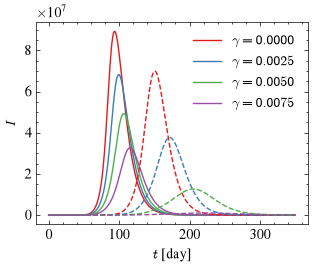

In [20]:
plt.figure()
gamma_colors = {}
for (beta, gamma), (ts, ys) in results_v.items():
    I_total = jnp.sum(ys[:, 2, :], axis=1)
    if gamma not in gamma_colors:
        line = plt.plot(ts, I_total, label=fr"$\gamma = {gamma:.4f}$")
        gamma_colors[gamma] = line[0].get_color()
    else:
        plt.plot(ts, I_total, color=gamma_colors[gamma], linestyle="--")
    total_infected = np.trapezoid(np.asarray(I_total), x=np.asarray(ts)) / 9
    total_population = jnp.sum(ys[0, :, :])
    print(f"beta = {beta:.4f}, gamma = {gamma:.4f}: approximately {total_infected/total_population:.2%} of the population infected")

plt.xlabel(r"$t$ [day]")
plt.ylabel("$I$")
plt.legend()
plt.savefig("../figures/vaccination_rates_combined.pdf")